# TP1 · Ejercicio 3 — Swin-Tiny en EuroSAT: LoRA vs. full fine-tuning

**Inteligencia Artificial y Aprendizaje Profundo II — UCA**
Prof. José Canelón, Ph.D.

**Integrantes:** Matías Adell, Agustín Giannice, Facundo Mazzola

Notebook pensado para **Google Colab con GPU T4**. Con `SMOKE_TEST = True` (o la variable de entorno `TP1_SMOKE_TEST=1`) corre en CPU con un subconjunto diminuto, solo para verificar que el código funciona de punta a punta.

**Índice**
0. Configuración (Colab, Drive, semilla, versiones, hiperparámetros)
1. Marco teórico: Swin Transformer, linear probe y LoRA
2. Datos: EuroSAT RGB y subset estratificado de 10k
3. Preprocesamiento: image processor y augmentation
4. Helpers: métricas, parámetros, memoria, tamaño en disco
5. `run_experiment`: probe, full y LoRA bajo las mismas condiciones
6. Entrenamiento de los tres modelos y curvas
7. Comparación: tabla, matriz de confusión y errores
8. Conclusiones (calculadas sobre las métricas)
9. Referencias

## 0. Configuración

Orden de la celda: (1) detección de Colab, instalación de librerías y montaje de Drive solo en Colab; (2) flag `SMOKE_TEST`; (3) carpeta base de artefactos (Drive o carpeta local); (4) semilla y dispositivo; (5) versiones e hiperparámetros.

Como en NB2 de la cátedra, se actualizan `transformers`, `datasets`, `accelerate`, `peft` y `evaluate`, y se desinstala `torchao` (la versión que trae Colab rompe a `peft`).

In [1]:
import os, sys, random, json, time, gc, shutil

# (1) Colab: instalación y Drive
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    %pip install -q -U transformers datasets accelerate peft evaluate
    %pip uninstall -q -y torchao

# (2) Modo smoke test: subset diminuto y 1 época para verificar en CPU
SMOKE_TEST = os.environ.get('TP1_SMOKE_TEST') == '1'

# (3) Carpeta base de checkpoints/artefactos
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/Colab_Notebooks/TP1_Adell_Giannice_Mazzola/ej3'
else:
    BASE = os.environ.get('TP1_LOCAL_DIR', './tp1_local') + '/ej3'
# El smoke test usa su propia subcarpeta y arranca siempre de cero
RUN_DIR = f'{BASE}/smoke' if SMOKE_TEST else BASE
if SMOKE_TEST:
    shutil.rmtree(RUN_DIR, ignore_errors=True)
os.makedirs(RUN_DIR, exist_ok=True)

# (4) Semilla y dispositivo
import numpy as np
import torch
import transformers
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
transformers.set_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_FP16 = torch.cuda.is_available()   # fp16 solo con GPU

# (5) Versiones e hiperparámetros
import datasets, peft, evaluate, torchvision, sklearn, pandas as pd, matplotlib
print('Python      :', sys.version.split()[0])
for lib in (torch, torchvision, transformers, datasets, peft, evaluate, sklearn, pd, matplotlib, np):
    print(f'{lib.__name__:<12}:', lib.__version__)
print('Dispositivo :', device, f'({torch.cuda.get_device_name(0)})' if device == 'cuda' else '')
print('SMOKE_TEST  :', SMOKE_TEST, '| RUN_DIR =', RUN_DIR)

HPARAMS = {
    'modelo': 'microsoft/swin-tiny-patch4-window7-224',
    'dataset': 'timm/eurosat-rgb',
    'n_train_subset': 100 if SMOKE_TEST else 10_000,
    'n_val': 50 if SMOKE_TEST else None,     # None = split oficial completo
    'n_test': 50 if SMOKE_TEST else None,
    'resolucion': 224,
    'batch_size': 32,
    'eval_batch_size': 64,
    'epocas_probe': 1,
    'epocas_ft': 1 if SMOKE_TEST else 3,     # full y LoRA
    'lr_probe': 1e-3,
    'lr_full': 5e-5,
    'lr_lora': 1e-3,
    'weight_decay': 0.01,
    'scheduler': 'cosine',
    'warmup_ratio': 0.1,
    'fp16': USE_FP16,
    'metric_for_best_model': 'accuracy',
    'lora_r': 8,
    'lora_alpha': 16,
    'lora_dropout': 0.05,
    'lora_target_modules': ['query', 'value'],   # se resuelven contra el modelo en la sección 5
    'lora_modules_to_save': ['classifier'],
    'seed': SEED,
}
pd.DataFrame(HPARAMS.items(), columns=['hiperparámetro', 'valor'])

Python      : 3.11.16
torch       : 2.14.0+cpu
torchvision : 0.29.0+cpu
transformers: 5.17.0
datasets    : 5.0.1
peft        : 0.21.0
evaluate    : 0.4.6
sklearn     : 1.9.1
pandas      : 3.0.6
matplotlib  : 3.11.2
numpy       : 2.4.6
Dispositivo : cpu 
SMOKE_TEST  : True | RUN_DIR = C:/Users/facum/tp1_cache/ej3/smoke


,hiperparámetro,valor
0,modelo,microsoft/swin-tiny-patch4-window7-224
1,dataset,timm/eurosat-rgb
2,n_train_subset,100
3,n_val,50
4,n_test,50
5,resolucion,224
6,batch_size,32
7,eval_batch_size,64
8,epocas_probe,1
9,epocas_ft,1


## 1. Marco teórico

### Swin Transformer (Liu et al., 2021)
El ViT (Dosovitskiy et al., 2021) parte la imagen en parches y aplica atención **global**, con costo cuadrático en el número de tokens y una única escala. Swin propone un Transformer **jerárquico**:

- **W-MSA**: la auto-atención se calcula dentro de ventanas locales no solapadas de $M\times M$ parches ($M=7$ en `swin-tiny-patch4-window7-224`), así el costo pasa de cuadrático a **lineal** en el número de parches.
- **SW-MSA**: en bloques alternos la partición se desplaza media ventana (cyclic shift + máscara), lo que conecta ventanas vecinas y permite que la información fluya globalmente.
- **Sesgo posicional relativo** $B$ dentro del softmax: $\text{Attention}(Q,K,V)=\text{softmax}\!\left(QK^\top/\sqrt{d}+B\right)V$, en lugar de embeddings absolutos.
- **Patch merging**: entre etapas se concatenan parches vecinos 2×2, se reduce la resolución a la mitad y se duplican los canales → 4 etapas multiescala, como una CNN.

Swin-Tiny: parches de 4×4, profundidades (2, 2, 6, 2), dimensión 96 → 768, ~28M parámetros, preentrenado en ImageNet-1k a 224×224. Para transferirlo a EuroSAT se **reemplaza la cabeza** de 1000 clases por una lineal de 10 (`ignore_mismatched_sizes=True`).

### Tres formas de adaptar el modelo
- **Linear probe** (el "antes"): encoder congelado y solo se entrena el clasificador lineal. Mide la calidad intrínseca de las features preentrenadas en esta tarea; es la referencia contra la que se miden las mejoras.
- **Full fine-tuning**: se actualizan todos los pesos. Suele dar la mejor calidad, pero la memoria de entrenamiento incluye pesos + gradientes + 2 momentos de Adam para *todos* los parámetros, y cada tarea requiere guardar una copia completa del modelo.
- **LoRA** (Hu et al., 2021): se congela $W_0$ y se aprende una actualización de bajo rango, $W = W_0 + \frac{\alpha}{r}BA$ con $B\in\mathbb{R}^{d\times r}$, $A\in\mathbb{R}^{r\times k}$, $r\ll\min(d,k)$. $B$ arranca en cero, así que el modelo inicial es idéntico al preentrenado. Agrega $r(d+k)$ parámetros por capa adaptada. Se inyecta en las proyecciones de atención **query** y **value**; la cabeza nueva se entrena completa vía `modules_to_save`. Tras entrenar, $BA$ puede fusionarse en $W_0$ (sin latencia extra), y el checkpoint guarda solo el adaptador (MB en lugar de GB).

### Mismas condiciones
Full y LoRA usan el **mismo subset de train** (el mismo objeto), la misma validación y test, resolución, batch, épocas, scheduler (warmup lineal + coseno), semilla y precisión. Solo cambian el learning rate (LoRA usa uno mayor, como en la cátedra) y qué parámetros se entrenan. Se entrenan 3 épocas con evaluación por época y `load_best_model_at_end=True` sobre la accuracy de validación (early stopping por selección del mejor checkpoint).

## 2. Datos: EuroSAT RGB

EuroSAT (Helber et al., 2019) son parches Sentinel-2 de 64×64 px en RGB, 10 clases de uso/cobertura del suelo. Se usa la versión `timm/eurosat-rgb` del Hub (parquet), que ya trae splits oficiales train / validation / test.

Por la consigna se entrena con un **subset fijo de 10.000 imágenes de train, estratificado por clase** (`train_test_split(stratify_by_column='label')` con semilla fija). Ese mismo objeto `train_sub` se usa para probe, full y LoRA. Validación y test son los splits oficiales completos.

In [2]:
from datasets import load_dataset

ds = load_dataset(HPARAMS['dataset'])
print(ds)
CLASSES = ds['train'].features['label'].names
NUM_LABELS = len(CLASSES)
id2label = {i: c for i, c in enumerate(CLASSES)}
label2id = {c: i for i, c in id2label.items()}
print(f'{NUM_LABELS} clases:', CLASSES)
print('Tamaño de imagen:', ds['train'][0]['image'].size, '| modo:', ds['train'][0]['image'].mode)

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 16200
    })
    validation: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
    test: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
})
10 clases: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']
Tamaño de imagen: (64, 64) | modo: RGB


In [3]:
def estratificado(split, n):
    # Subset estratificado por clase con semilla fija
    if n is None or n >= len(split):
        return split
    return split.train_test_split(train_size=n, stratify_by_column='label', seed=SEED)['train']

train_sub = estratificado(ds['train'], HPARAMS['n_train_subset'])
val_ds = estratificado(ds['validation'], HPARAMS['n_val'])
test_ds = estratificado(ds['test'], HPARAMS['n_test'])
print(f'train_sub: {len(train_sub)} | validation: {len(val_ds)} | test: {len(test_ds)}')
print('Primeros image_id del subset (reproducible con la semilla):', train_sub[:3]['image_id'])

train_sub: 100 | validation: 50 | test: 50
Primeros image_id del subset (reproducible con la semilla): ['Pasture_1775', 'Pasture_1751', 'River_239']


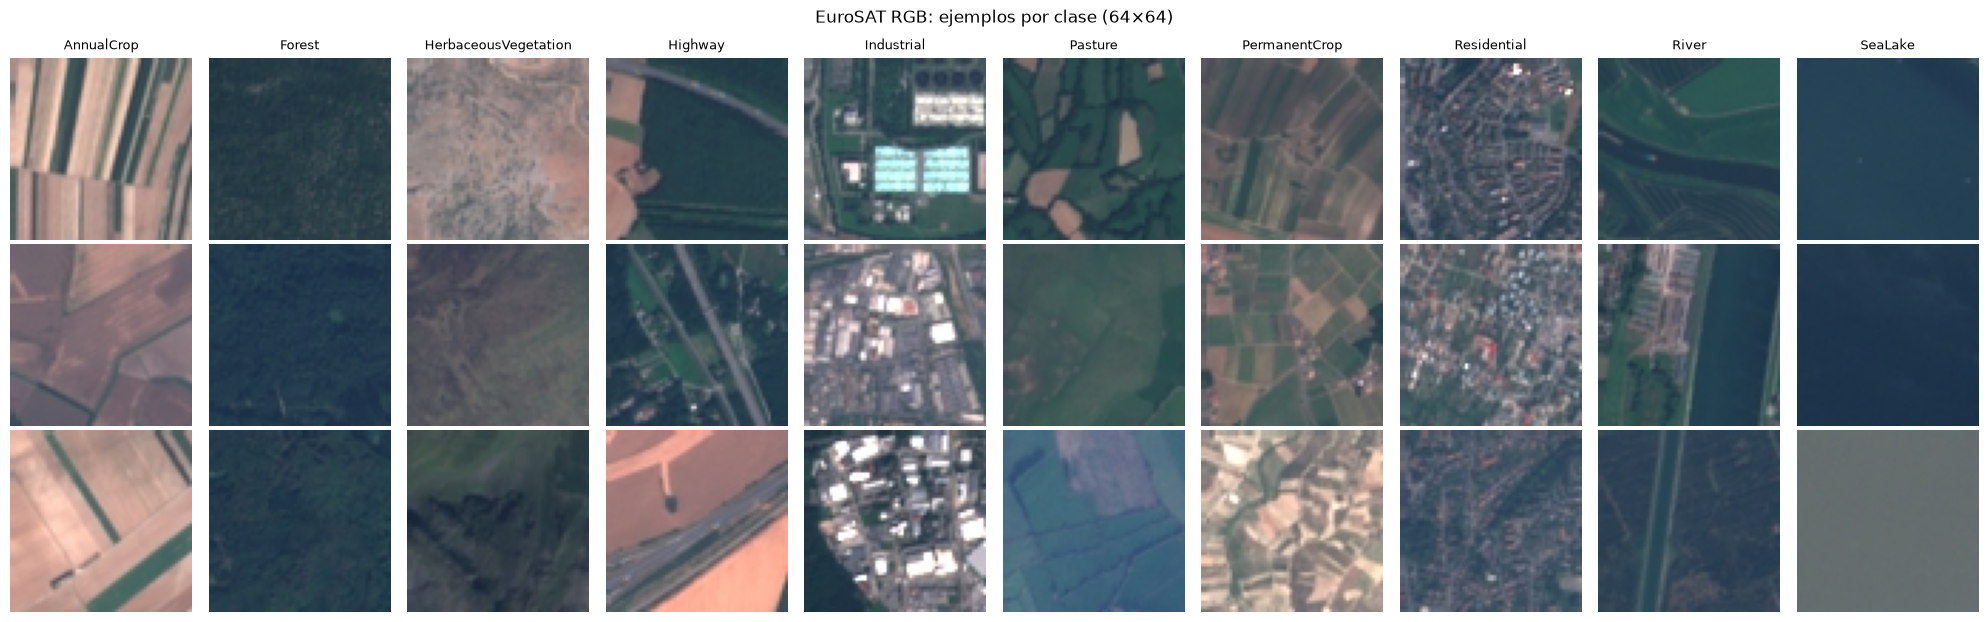

In [4]:
import matplotlib.pyplot as plt

# Una fila de ejemplos por clase (3 imágenes de cada una)
labels_train = np.array(list(ds['train']['label']))
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, NUM_LABELS, figsize=(2 * NUM_LABELS, 6.3))
for c in range(NUM_LABELS):
    idx = rng.choice(np.where(labels_train == c)[0], 3, replace=False)
    for r, i in enumerate(idx):
        axes[r, c].imshow(ds['train'][int(i)]['image'])
        axes[r, c].axis('off')
    axes[0, c].set_title(CLASSES[c], fontsize=9)
plt.suptitle('EuroSAT RGB: ejemplos por clase (64×64)')
plt.tight_layout(); plt.show()

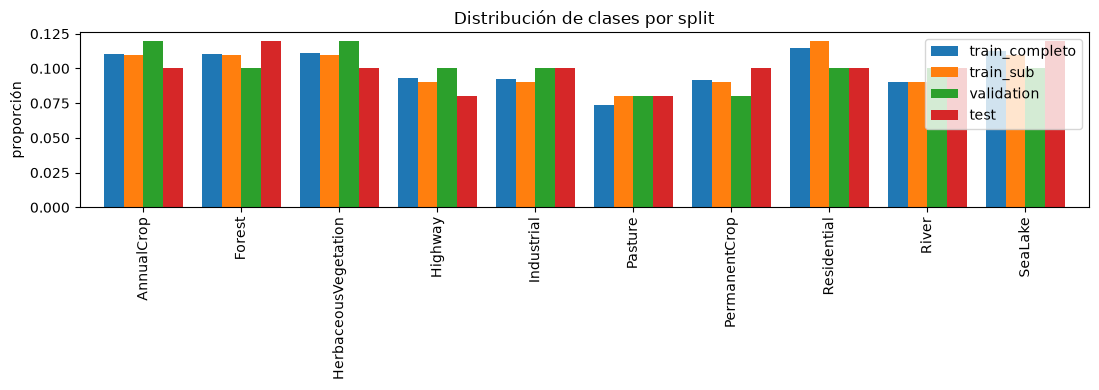

Máxima diferencia de proporción train_completo vs. train_sub: 0.0062


,train_completo,train_sub,validation,test
AnnualCrop,0.1106,0.11,0.12,0.10
Forest,0.1103,0.11,0.10,0.12
HerbaceousVegetation,0.1110,0.11,0.12,0.10
Highway,0.0929,0.09,0.10,0.08
Industrial,0.0921,0.09,0.10,0.10
Pasture,0.0738,0.08,0.08,0.08
PermanentCrop,0.0914,0.09,0.08,0.10
Residential,0.1150,0.12,0.10,0.10
River,0.0901,0.09,0.10,0.10
SeaLake,0.1128,0.11,0.10,0.12


In [5]:
# Distribución de clases: train completo vs. subset estratificado (en proporción)
dist = pd.DataFrame({
    'train_completo': pd.Series(labels_train).value_counts(normalize=True).sort_index(),
    'train_sub': pd.Series(list(train_sub['label'])).value_counts(normalize=True).sort_index(),
    'validation': pd.Series(list(val_ds['label'])).value_counts(normalize=True).sort_index(),
    'test': pd.Series(list(test_ds['label'])).value_counts(normalize=True).sort_index(),
}).fillna(0)
dist.index = CLASSES
dist.plot.bar(figsize=(11, 4), width=0.8)
plt.ylabel('proporción'); plt.title('Distribución de clases por split')
plt.tight_layout(); plt.show()
print('Máxima diferencia de proporción train_completo vs. train_sub:',
      f"{(dist['train_completo'] - dist['train_sub']).abs().max():.4f}")
dist.round(4)

## 3. Preprocesamiento: image processor + augmentation

Swin-Tiny fue preentrenado a 224×224 con normalización de ImageNet. Del `AutoImageProcessor` del checkpoint se leen el **tamaño**, la **media**, el **desvío** y el método de **interpolación**, y con ellos se arman dos pipelines de torchvision:

- **train**: `RandomResizedCrop(224, scale=(0.8, 1))` (hace el upscale 64 → 224 y un recorte leve), flips horizontal y vertical, rotación leve (±15°), `ToTensor` y `Normalize`. En imágenes satelitales no hay "arriba" ni "abajo": los flips verticales y las rotaciones generan vistas igual de válidas que las originales.
- **eval** (validación/test): solo `Resize(224)` + `Normalize`, igual a lo que hace el image processor.

Se aplican on-the-fly con `with_transform`, así no se materializan 10k tensores de 3×224×224 en RAM. Se verifica que el pipeline de eval coincide con la salida del image processor.

In [6]:
from transformers import AutoImageProcessor
from torchvision import transforms as T

processor = AutoImageProcessor.from_pretrained(HPARAMS['modelo'])
IMG_SIZE = processor.size['height']
MEAN, STD = list(processor.image_mean), list(processor.image_std)
INTERP = T.InterpolationMode.BICUBIC if int(getattr(processor, 'resample', 3)) == 3 else T.InterpolationMode.BILINEAR
print(type(processor).__name__, '| tamaño:', IMG_SIZE, '| mean:', MEAN, '| std:', STD, '| interpolación:', INTERP.value)

train_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0), interpolation=INTERP),
    T.RandomHorizontalFlip(),
    T.RandomVerticalFlip(),
    T.RandomRotation(15, interpolation=T.InterpolationMode.BILINEAR),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])
eval_tf = T.Compose([
    T.Resize((IMG_SIZE, IMG_SIZE), interpolation=INTERP),
    T.ToTensor(),
    T.Normalize(MEAN, STD),
])

def make_transform(tf):
    def _apply(batch):
        return {'pixel_values': [tf(img.convert('RGB')) for img in batch['image']],
                'labels': batch['label']}
    return _apply

train_t = train_sub.with_transform(make_transform(train_tf))
val_t = val_ds.with_transform(make_transform(eval_tf))
test_t = test_ds.with_transform(make_transform(eval_tf))

# Chequeo: el pipeline de eval reproduce al image processor
img0 = test_ds[0]['image'].convert('RGB')
px_proc = processor(images=img0, return_tensors='pt')['pixel_values'][0]
px_ours = eval_tf(img0)
print('Forma:', tuple(px_ours.shape), '| diferencia media absoluta vs. processor:',
      f'{(px_proc - px_ours).abs().mean().item():.4f}')

def collate_fn(batch):
    return {'pixel_values': torch.stack([b['pixel_values'] for b in batch]),
            'labels': torch.tensor([b['labels'] for b in batch])}

ViTImageProcessor | tamaño: 224 | mean: [0.485, 0.456, 0.406] | std: [0.229, 0.224, 0.225] | interpolación: bicubic
Forma: (3, 224, 224) | diferencia media absoluta vs. processor: 0.0002


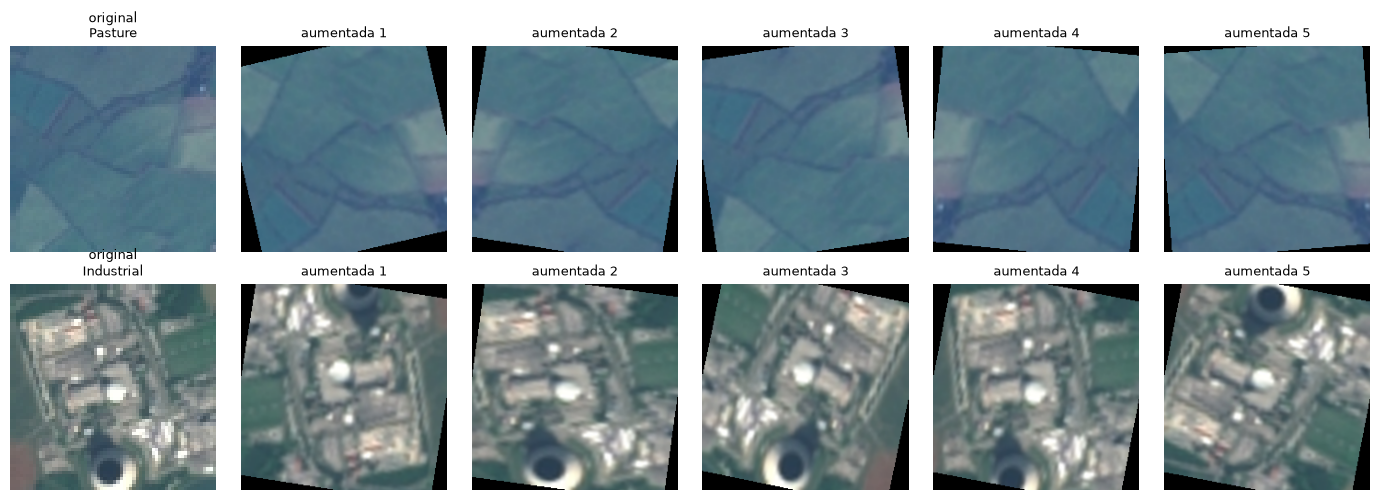

In [7]:
# Visualización de la augmentation: una imagen original y 5 vistas aumentadas
def desnormalizar(x):
    x = x * torch.tensor(STD)[:, None, None] + torch.tensor(MEAN)[:, None, None]
    return x.clamp(0, 1).permute(1, 2, 0).numpy()

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for r in range(2):
    ex = train_sub[r * 7]
    axes[r, 0].imshow(ex['image']); axes[r, 0].set_title(f"original\n{CLASSES[ex['label']]}", fontsize=9)
    for k in range(1, 6):
        axes[r, k].imshow(desnormalizar(train_tf(ex['image'].convert('RGB'))))
        axes[r, k].set_title(f'aumentada {k}', fontsize=9)
for a in axes.ravel():
    a.axis('off')
plt.tight_layout(); plt.show()

## 4. Helpers compartidos

- `compute_metrics`: accuracy y F1-macro con `evaluate`.
- `n_trainable` / `n_total`: conteo de parámetros (equivalente a `print_trainable_parameters` para full y probe).
- `dir_size_mb`: tamaño del checkpoint en disco (como en NB2).
- Memoria: `torch.cuda.reset_peak_memory_stats()` antes de entrenar y `torch.cuda.max_memory_allocated()` después; en CPU se reporta N/A. Antes de cada experimento se libera el modelo anterior para que el pico medido corresponda solo al experimento en curso.

In [8]:
acc_metric = evaluate.load('accuracy')
f1_metric = evaluate.load('f1')

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {'accuracy': acc_metric.compute(predictions=preds, references=labels)['accuracy'],
            'f1_macro': f1_metric.compute(predictions=preds, references=labels, average='macro')['f1']}

def n_trainable(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

def n_total(m):
    return sum(p.numel() for p in m.parameters())

def dir_size_mb(path):
    tot = sum(os.path.getsize(os.path.join(dp, f)) for dp, _, fs in os.walk(path) for f in fs)
    return tot / 1e6

def liberar_memoria():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 5. `run_experiment(mode, lr, epochs)`

Una única función arma el modelo y entrena, así las tres variantes comparten exactamente los mismos `TrainingArguments` salvo el learning rate (y las épocas del probe):

- `probe`: se congela todo `swin.*`; solo `classifier` es entrenable.
- `full`: todos los parámetros entrenables.
- `lora`: `get_peft_model` con `LoraConfig(r=8, lora_alpha=16, lora_dropout=0.05, target_modules=[query, value], modules_to_save=['classifier'])`.

**Nombres de los módulos de atención.** En `transformers` 4.x las proyecciones de Swin se llaman `attention.self.query / key / value`; en `transformers` ≥ 5 se renombraron a `q_proj / k_proj / v_proj`. La celda siguiente inspecciona `named_modules()` y resuelve qué nombres usar para apuntar a **query y value** en la versión instalada.

**Recarga de checkpoints (bug de `transformers` 5.x).** Los checkpoints se guardan con los nombres de pesos "legacy" (`attention.self.query`, ...) pero el `Trainer` los recarga con `load_state_dict(strict=False)` sin convertirlos a los nombres nuevos (`q_proj`, ...): el backbone de Swin **no se recarga** (solo emite un aviso, que acá se silencia). Con `load_best_model_at_end` eso dejaría en full fine-tuning el backbone de la última época con la cabeza de la mejor, y al reanudar volvería al backbone preentrenado. Por eso, para probe y full, `cargar_pesos` recarga el checkpoint con `from_pretrained` (que sí convierte los nombres) antes de reanudar y después de entrenar. Los adaptadores LoRA se guardan y recargan con `peft` y no tienen este problema.

**Reanudación.** Se guarda un checkpoint por época en Drive (`save_strategy='epoch'`); si la sesión se corta, al volver a correr se reanuda desde el último checkpoint (`resume_from_checkpoint`). Además, al terminar cada experimento se guarda un JSON con sus métricas, historia y predicciones: si existe, el experimento no se vuelve a entrenar (el smoke test siempre arranca de cero).

In [9]:
from transformers import AutoModelForImageClassification, TrainingArguments, Trainer
from transformers.trainer_utils import get_last_checkpoint
from peft import LoraConfig, get_peft_model
import logging
# Los avisos de claves del Trainer al recargar checkpoints se resuelven con cargar_pesos (ver arriba)
logging.getLogger('transformers.trainer').setLevel(logging.ERROR)

def load_base_model():
    return AutoModelForImageClassification.from_pretrained(
        HPARAMS['modelo'], num_labels=NUM_LABELS, id2label=id2label, label2id=label2id,
        ignore_mismatched_sizes=True)

# Resolución de los nombres de query/value en la versión instalada de transformers
_m = load_base_model()
attn_linear = sorted({n.split('.')[-1] for n, mod in _m.named_modules()
                      if isinstance(mod, torch.nn.Linear) and '.attention.' in n})
print('Capas lineales dentro de la atención de Swin:', attn_linear)
LORA_TARGETS = ['query', 'value'] if 'query' in attn_linear else ['q_proj', 'v_proj']
print('target_modules de LoRA (query y value):', LORA_TARGETS)
HPARAMS['lora_target_modules'] = LORA_TARGETS
print('Ejemplo:', [n for n, _ in _m.named_modules() if n.endswith(tuple(LORA_TARGETS))][:2])
print(f'Parámetros totales de Swin-Tiny con cabeza de {NUM_LABELS} clases: {n_total(_m):,}')
del _m; liberar_memoria()

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Capas lineales dentro de la atención de Swin: ['k_proj', 'o_proj', 'q_proj', 'v_proj']
target_modules de LoRA (query y value): ['q_proj', 'v_proj']
Ejemplo: ['swin.encoder.layers.0.blocks.0.attention.q_proj', 'swin.encoder.layers.0.blocks.0.attention.v_proj']
Parámetros totales de Swin-Tiny con cabeza de 10 clases: 27,527,044


In [10]:
def build_model(mode):
    model = load_base_model()
    if mode == 'probe':
        for name, p in model.named_parameters():
            p.requires_grad = name.startswith('classifier')
    elif mode == 'lora':
        lora_cfg = LoraConfig(r=HPARAMS['lora_r'], lora_alpha=HPARAMS['lora_alpha'],
                              lora_dropout=HPARAMS['lora_dropout'], target_modules=LORA_TARGETS,
                              modules_to_save=HPARAMS['lora_modules_to_save'])
        model = get_peft_model(model, lora_cfg)
        model.print_trainable_parameters()
    return model

def cargar_pesos(model, ckpt_dir):
    # from_pretrained convierte los nombres legacy del checkpoint; strict=True verifica que no falte nada
    ref = AutoModelForImageClassification.from_pretrained(ckpt_dir)
    model.load_state_dict(ref.state_dict(), strict=True)
    del ref

def make_args(out_dir, lr, epochs):
    # Idénticos para probe, full y LoRA salvo lr y epochs
    steps_per_epoch = -(-len(train_t) // HPARAMS['batch_size'])
    return TrainingArguments(
        output_dir=out_dir,
        per_device_train_batch_size=HPARAMS['batch_size'],
        per_device_eval_batch_size=HPARAMS['eval_batch_size'],
        num_train_epochs=epochs,
        learning_rate=lr,
        weight_decay=HPARAMS['weight_decay'],
        lr_scheduler_type=HPARAMS['scheduler'],
        warmup_steps=HPARAMS['warmup_ratio'],       # float < 1 = fracción de los pasos totales
        eval_strategy='epoch',
        save_strategy='epoch',
        save_total_limit=2,
        load_best_model_at_end=True,
        metric_for_best_model=HPARAMS['metric_for_best_model'],
        greater_is_better=True,
        logging_strategy='steps',
        logging_steps=max(1, steps_per_epoch // 10),
        fp16=HPARAMS['fp16'],
        remove_unused_columns=False,                # conserva 'image' para el transform
        label_names=['labels'],
        dataloader_num_workers=2 if IN_COLAB else 0,
        dataloader_pin_memory=torch.cuda.is_available(),
        report_to='none',
        seed=SEED,
    )

def run_experiment(mode, lr, epochs):
    out_dir = f'{RUN_DIR}/out_{mode}'
    ckpt_dir = f'{RUN_DIR}/ckpt_{mode}'
    res_path = f'{RUN_DIR}/resultados_{mode}.json'
    if os.path.exists(res_path) and not SMOKE_TEST:
        print(f'[{mode}] resultados previos encontrados en {res_path}: no se reentrena.')
        with open(res_path) as f:
            return json.load(f)

    liberar_memoria()
    transformers.set_seed(SEED)
    model = build_model(mode)
    trainable, total = n_trainable(model), n_total(model)
    print(f'[{mode}] parámetros entrenables: {trainable:,} / {total:,} ({100 * trainable / total:.4f}%)')

    trainer = Trainer(model=model, args=make_args(out_dir, lr, epochs),
                      train_dataset=train_t, eval_dataset=val_t, data_collator=collate_fn,
                      processing_class=processor, compute_metrics=compute_metrics)
    last_ckpt = get_last_checkpoint(out_dir) if os.path.isdir(out_dir) else None
    if last_ckpt:
        print(f'[{mode}] reanudando desde {last_ckpt}')
        if mode != 'lora':
            cargar_pesos(trainer.model, last_ckpt)

    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    t0 = time.perf_counter()
    trainer.train(resume_from_checkpoint=last_ckpt)
    train_time = time.perf_counter() - t0
    peak_gb = torch.cuda.max_memory_allocated() / 1e9 if torch.cuda.is_available() else None
    best_ckpt = trainer.state.best_model_checkpoint
    if mode != 'lora' and best_ckpt:
        cargar_pesos(trainer.model, best_ckpt)
    print(f'[{mode}] mejor checkpoint: {best_ckpt} (accuracy de validación = {trainer.state.best_metric:.4f})')

    # Mejor modelo (cargado por load_best_model_at_end) evaluado en validación y test
    val_metrics = trainer.evaluate(val_t)
    pred = trainer.predict(test_t)

    # Guardado: full/probe = modelo completo; LoRA = solo el adaptador (+ cabeza)
    if mode == 'lora':
        trainer.model.save_pretrained(ckpt_dir)
    else:
        trainer.save_model(ckpt_dir)

    res = {
        'mode': mode, 'lr': lr, 'epochs': epochs,
        'trainable': trainable, 'total': total,
        'train_time_s': train_time, 'peak_mem_gb': peak_gb,
        'ckpt_mb': dir_size_mb(ckpt_dir),
        'val_accuracy': val_metrics['eval_accuracy'], 'val_f1_macro': val_metrics['eval_f1_macro'],
        'test_accuracy': pred.metrics['test_accuracy'], 'test_f1_macro': pred.metrics['test_f1_macro'],
        'y_true': pred.label_ids.tolist(), 'y_pred': pred.predictions.argmax(-1).tolist(),
        'log_history': trainer.state.log_history,
        'resumed_from': last_ckpt,
        'best_checkpoint': best_ckpt,
    }
    with open(res_path, 'w') as f:
        json.dump(res, f)
    print(f"[{mode}] acc test = {res['test_accuracy']:.4f} | F1-macro test = {res['test_f1_macro']:.4f} "
          f"| tiempo = {train_time:.1f} s | checkpoint = {res['ckpt_mb']:.1f} MB")
    del trainer, model; liberar_memoria()
    return res

## 6. Entrenamiento

### 6.1 Antes del fine-tuning: linear probe (1 época)
Backbone congelado, solo se entrena la cabeza lineal. Su accuracy en test es la referencia "antes".

In [11]:
res_probe = run_experiment('probe', HPARAMS['lr_probe'], HPARAMS['epocas_probe'])

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


[probe] parámetros entrenables: 7,690 / 27,527,044 (0.0279%)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,2.353245,2.202122,0.300000,0.240791


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[probe] mejor checkpoint: C:/Users/facum/tp1_cache/ej3/smoke/out_probe\checkpoint-4 (accuracy de validación = 0.3000)


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
2.353245,2.202122,1,0.300000,0.240791


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[probe] acc test = 0.2200 | F1-macro test = 0.1775 | tiempo = 7.2 s | checkpoint = 110.1 MB


### 6.2 Full fine-tuning
Todos los pesos entrenables, LR bajo (5e-5) para no destruir las features preentrenadas.

In [12]:
res_full = run_experiment('full', HPARAMS['lr_full'], HPARAMS['epocas_ft'])

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


[full] parámetros entrenables: 27,527,044 / 27,527,044 (100.0000%)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,2.145685,2.121516,0.400000,0.303326


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[full] mejor checkpoint: C:/Users/facum/tp1_cache/ej3/smoke/out_full\checkpoint-4 (accuracy de validación = 0.4000)


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
2.145685,2.121516,1,0.400000,0.303326


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[full] acc test = 0.3400 | F1-macro test = 0.2701 | tiempo = 15.7 s | checkpoint = 110.1 MB


### 6.3 LoRA
Backbone congelado, adaptadores de rango 8 en query/value y cabeza entrenable. LR mayor (1e-3), como en la cátedra: la actualización de bajo rango parte de cero y tiene pocos parámetros.

In [13]:
res_lora = run_experiment('lora', HPARAMS['lr_lora'], HPARAMS['epocas_ft'])
RESULTADOS = {'probe': res_probe, 'full': res_full, 'lora': res_lora}

[transformers] You passed `num_labels=10` which is incompatible to the `id2label` map of length `1000`.


Loading weights:   0%|          | 0/221 [00:00<?, ?it/s]

[transformers] SwinForImageClassification LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status   |                                                                                           
------------------+----------+-------------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000]) vs model:torch.Size([10])          
classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([1000, 768]) vs model:torch.Size([10, 768])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


trainable params: 149,002 || all params: 27,676,046 || trainable%: 0.5384
[lora] parámetros entrenables: 149,002 / 27,676,046 (0.5384%)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,2.276948,2.180481,0.320000,0.249402


[lora] mejor checkpoint: C:/Users/facum/tp1_cache/ej3/smoke/out_lora\checkpoint-4 (accuracy de validación = 0.3200)


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro
2.276948,2.180481,1,0.320000,0.249402


[lora] acc test = 0.3000 | F1-macro test = 0.2242 | tiempo = 13.7 s | checkpoint = 0.6 MB


### 6.4 Curvas de entrenamiento y validación
Se leen de `trainer.state.log_history` (guardado en cada JSON): loss de train por pasos de logging, y loss y accuracy de validación por época.

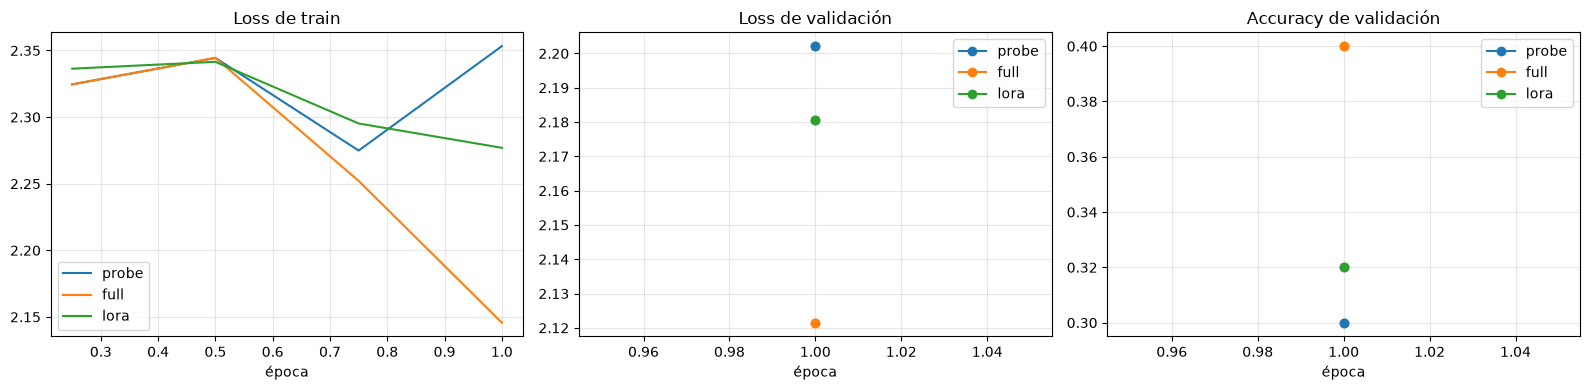

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for mode, res in RESULTADOS.items():
    hist = res['log_history']
    tr = [(h['epoch'], h['loss']) for h in hist if 'loss' in h and 'eval_loss' not in h]
    ev = [(h['epoch'], h['eval_loss'], h['eval_accuracy']) for h in hist if 'eval_accuracy' in h]
    if tr:
        axes[0].plot(*zip(*tr), label=mode)
    if ev:
        e, l, a = zip(*ev)
        axes[1].plot(e, l, 'o-', label=mode)
        axes[2].plot(e, a, 'o-', label=mode)
for ax, t in zip(axes, ['Loss de train', 'Loss de validación', 'Accuracy de validación']):
    ax.set_title(t); ax.set_xlabel('época'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 7. Comparación

La tabla reúne, para cada método: accuracy y F1-macro en validación (mejor época) y test, el **delta** contra el linear probe (antes → después), parámetros entrenables (absoluto y %), memoria de GPU pico, tamaño del checkpoint (en MB y GB) y tiempo de entrenamiento.

In [15]:
acc_probe = res_probe['test_accuracy']
filas = []
for mode, res in RESULTADOS.items():
    filas.append({
        'método': mode,
        'acc_val': res['val_accuracy'],
        'acc_test': res['test_accuracy'],
        'f1_macro_test': res['test_f1_macro'],
        'Δacc_vs_probe': res['test_accuracy'] - acc_probe,
        'params_entrenables': res['trainable'],
        '%_entrenables': 100 * res['trainable'] / res['total'],
        'mem_pico_GB': 'N/A' if res['peak_mem_gb'] is None else round(res['peak_mem_gb'], 2),
        'checkpoint_MB': res['ckpt_mb'],
        'checkpoint_GB': res['ckpt_mb'] / 1e3,
        'tiempo_s': res['train_time_s'],
    })
tabla = pd.DataFrame(filas).set_index('método')
tabla.style.format({'acc_val': '{:.4f}', 'acc_test': '{:.4f}', 'f1_macro_test': '{:.4f}',
                    'Δacc_vs_probe': '{:+.4f}', 'params_entrenables': '{:,}', '%_entrenables': '{:.3f}',
                    'checkpoint_MB': '{:.1f}', 'checkpoint_GB': '{:.3f}', 'tiempo_s': '{:.1f}'})

,acc_val,acc_test,f1_macro_test,Δacc_vs_probe,params_entrenables,%_entrenables,mem_pico_GB,checkpoint_MB,checkpoint_GB,tiempo_s
método,,,,,,,,,,
probe,0.3000,0.2200,0.1775,+0.0000,"7,690",0.028,N/A,110.1,0.110,7.2
full,0.4000,0.3400,0.2701,+0.1200,"27,527,044",100.000,N/A,110.1,0.110,15.7
lora,0.3200,0.3000,0.2242,+0.0800,"149,002",0.538,N/A,0.6,0.001,13.7


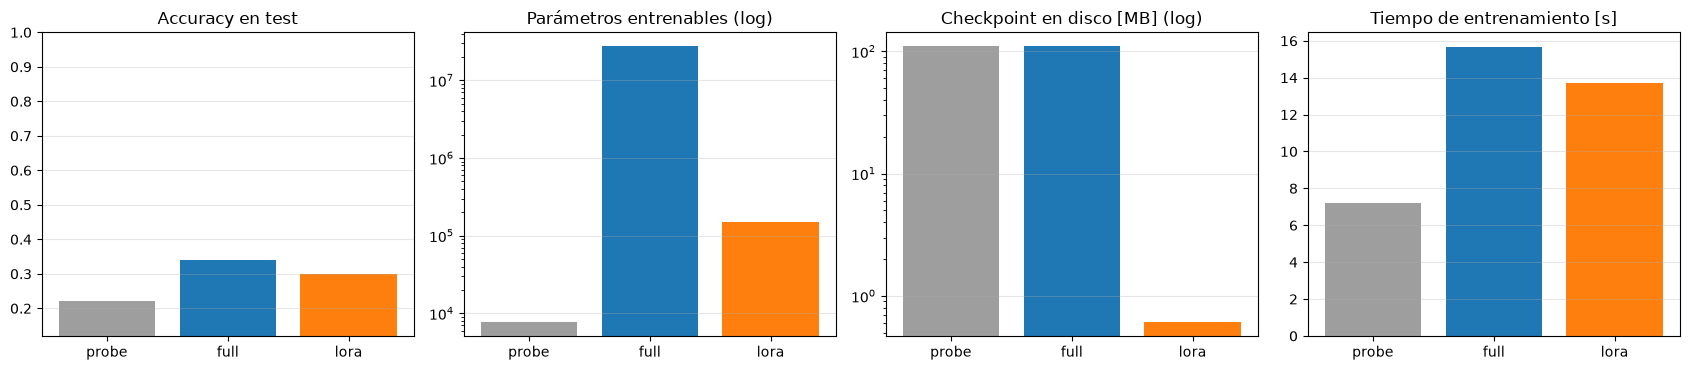

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
colores = ['#9e9e9e', '#1f77b4', '#ff7f0e']
metodos = tabla.index.tolist()
axes[0].bar(metodos, tabla['acc_test'], color=colores); axes[0].set_title('Accuracy en test')
axes[0].set_ylim(max(0, tabla['acc_test'].min() - 0.1), 1)
axes[1].bar(metodos, tabla['params_entrenables'], color=colores); axes[1].set_yscale('log')
axes[1].set_title('Parámetros entrenables (log)')
axes[2].bar(metodos, tabla['checkpoint_MB'], color=colores); axes[2].set_yscale('log')
axes[2].set_title('Checkpoint en disco [MB] (log)')
axes[3].bar(metodos, tabla['tiempo_s'], color=colores); axes[3].set_title('Tiempo de entrenamiento [s]')
for ax in axes:
    ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

### 7.1 Matriz de confusión y reporte por clase del mejor modelo
Se elige automáticamente el mejor entre full y LoRA según la accuracy en test.

Mejor modelo en test: full (accuracy = 0.3400)



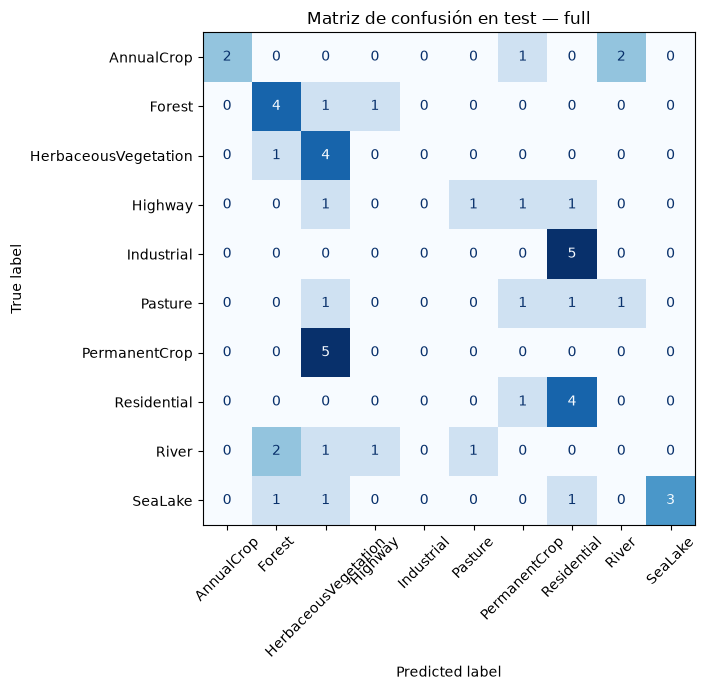

                      precision    recall  f1-score   support

          AnnualCrop     1.0000    0.4000    0.5714         5
              Forest     0.5000    0.6667    0.5714         6
HerbaceousVegetation     0.2857    0.8000    0.4211         5
             Highway     0.0000    0.0000    0.0000         4
          Industrial     0.0000    0.0000    0.0000         5
             Pasture     0.0000    0.0000    0.0000         4
       PermanentCrop     0.0000    0.0000    0.0000         5
         Residential     0.3333    0.8000    0.4706         5
               River     0.0000    0.0000    0.0000         5
             SeaLake     1.0000    0.5000    0.6667         6

            accuracy                         0.3400        50
           macro avg     0.3119    0.3167    0.2701        50
        weighted avg     0.3419    0.3400    0.2949        50



In [17]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

mejor = max(['full', 'lora'], key=lambda m: RESULTADOS[m]['test_accuracy'])
y_true = np.array(RESULTADOS[mejor]['y_true'])
y_pred = np.array(RESULTADOS[mejor]['y_pred'])
print(f'Mejor modelo en test: {mejor} (accuracy = {RESULTADOS[mejor]["test_accuracy"]:.4f})\n')

cm = confusion_matrix(y_true, y_pred, labels=range(NUM_LABELS))
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
ax.set_title(f'Matriz de confusión en test — {mejor}')
plt.tight_layout(); plt.show()

print(classification_report(y_true, y_pred, labels=range(NUM_LABELS), target_names=CLASSES,
                            digits=4, zero_division=0))

Confusiones más frecuentes (real → predicha):
         PermanentCrop → HerbaceousVegetation: 5
            Industrial → Residential         : 5
                 River → Forest              : 2
            AnnualCrop → River               : 2
               SeaLake → Residential         : 1

Errores en test: 33 de 50 (66.00%)


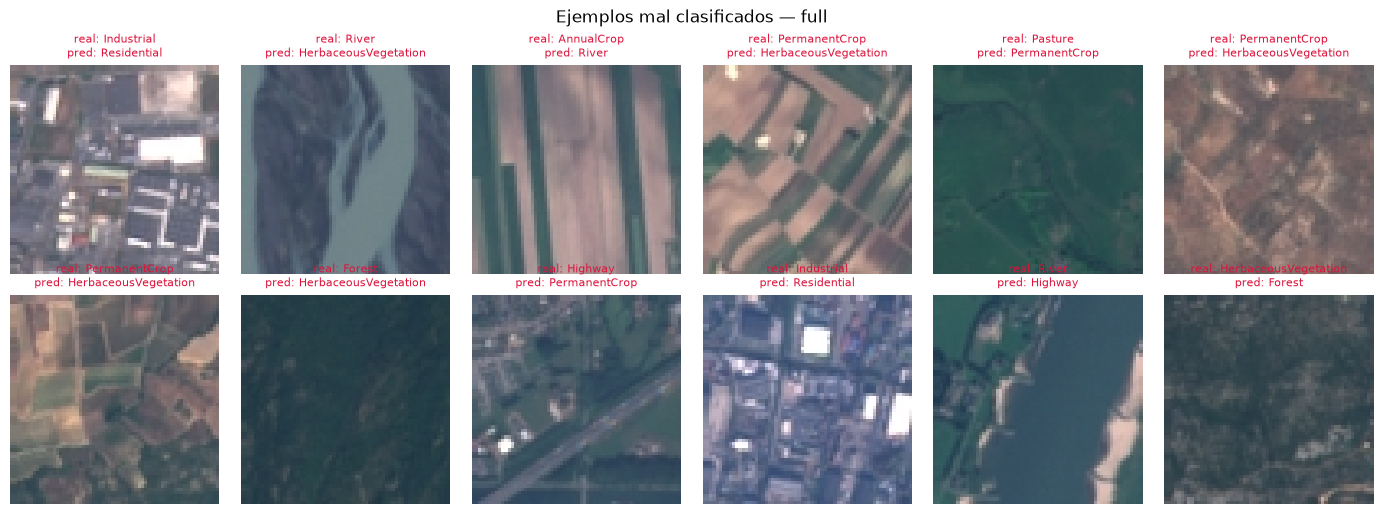

In [18]:
# Pares de clases más confundidos y ejemplos mal clasificados
cm_off = cm.copy(); np.fill_diagonal(cm_off, 0)
pares = sorted(((cm_off[i, j], CLASSES[i], CLASSES[j]) for i in range(NUM_LABELS)
                for j in range(NUM_LABELS) if cm_off[i, j] > 0), reverse=True)[:5]
print('Confusiones más frecuentes (real → predicha):')
for n, a, b in pares:
    print(f'  {a:>20} → {b:<20}: {n}')

errores = np.where(y_true != y_pred)[0]
print(f'\nErrores en test: {len(errores)} de {len(y_true)} ({100 * len(errores) / len(y_true):.2f}%)')
n_show = min(12, len(errores))
if n_show:
    sel = np.random.default_rng(SEED).choice(errores, n_show, replace=False)
    fig, axes = plt.subplots(2, 6, figsize=(14, 5.2))
    for ax in axes.ravel():
        ax.axis('off')
    for ax, i in zip(axes.ravel(), sel):
        ax.imshow(test_ds[int(i)]['image'])
        ax.set_title(f'real: {CLASSES[y_true[i]]}\npred: {CLASSES[y_pred[i]]}', fontsize=8, color='crimson')
    plt.suptitle(f'Ejemplos mal clasificados — {mejor}')
    plt.tight_layout(); plt.show()

## 8. Conclusiones

Las conclusiones se calculan a partir de las métricas obtenidas en este run (no hay números escritos a mano).

In [19]:
full, lora, probe = RESULTADOS['full'], RESULTADOS['lora'], RESULTADOS['probe']
gap = full['test_accuracy'] - lora['test_accuracy']
ganador = 'full fine-tuning' if gap > 0 else ('LoRA' if gap < 0 else 'empate')

print('1) Antes vs. después del fine-tuning (accuracy en test)')
print(f"   - Linear probe (antes): {probe['test_accuracy']:.4f}")
for m in ('full', 'lora'):
    r = RESULTADOS[m]
    d = r['test_accuracy'] - probe['test_accuracy']
    print(f"   - {m:<4}: {r['test_accuracy']:.4f}  (Δ = {d:+.4f}, {100 * d / max(probe['test_accuracy'], 1e-9):+.1f}% relativo al probe)")

print(f"\n2) Full vs. LoRA: gana {ganador}; diferencia de accuracy = {abs(gap):.4f} "
      f"({100 * abs(gap):.2f} puntos porcentuales); F1-macro full = {full['test_f1_macro']:.4f}, LoRA = {lora['test_f1_macro']:.4f}.")
if lora['test_accuracy'] > 0:
    print(f"   LoRA retiene el {100 * lora['test_accuracy'] / max(full['test_accuracy'], 1e-9):.1f}% de la accuracy de full.")

ratio_params = full['trainable'] / lora['trainable']
print(f"\n3) Parámetros entrenables: full = {full['trainable']:,} vs. LoRA = {lora['trainable']:,} "
      f"({100 * lora['trainable'] / lora['total']:.3f}% del modelo) → full entrena {ratio_params:.0f}× más parámetros.")

ratio_size = full['ckpt_mb'] / lora['ckpt_mb']
print(f"\n4) Checkpoint: full = {full['ckpt_mb'] / 1e3:.3f} GB ({full['ckpt_mb']:.1f} MB) vs. adaptador LoRA = {lora['ckpt_mb']:.2f} MB "
      f"→ el adaptador es {ratio_size:.0f}× más chico.")

if full['peak_mem_gb'] is not None and lora['peak_mem_gb'] is not None:
    print(f"\n5) Memoria de GPU pico: full = {full['peak_mem_gb']:.2f} GB, LoRA = {lora['peak_mem_gb']:.2f} GB, "
          f"probe = {probe['peak_mem_gb']:.2f} GB → LoRA usa {100 * (1 - lora['peak_mem_gb'] / full['peak_mem_gb']):.1f}% menos que full.")
else:
    print('\n5) Memoria de GPU: N/A (corrida sin CUDA).')

print(f"\n6) Tiempo de entrenamiento: full = {full['train_time_s']:.1f} s, LoRA = {lora['train_time_s']:.1f} s "
      f"(LoRA/full = {lora['train_time_s'] / max(full['train_time_s'], 1e-9):.2f}).")
if full.get('resumed_from') or lora.get('resumed_from'):
    print('   Atención: algún experimento se reanudó desde un checkpoint; su tiempo y memoria corresponden solo al tramo final.')

print('\n7) Lectura:')
if abs(gap) <= 0.01:
    print(f'   LoRA queda a {100 * abs(gap):.2f} pp de full (≤ 1 pp) entrenando {ratio_params:.0f}× menos parámetros '
          f'y con un checkpoint {ratio_size:.0f}× más liviano: la adaptación a EuroSAT es de baja dimensión intrínseca.')
elif gap > 0:
    print(f'   Full supera a LoRA por {100 * gap:.2f} pp: con 10k imágenes y un dominio (satelital) alejado de ImageNet, '
          f'ajustar todo el backbone aporta capacidad extra, a cambio de {ratio_params:.0f}× más parámetros y {ratio_size:.0f}× más disco.')
else:
    print(f'   LoRA supera a full por {100 * -gap:.2f} pp: al congelar el backbone regulariza y evita sobreajustar el subset de 10k.')
mejora_min = min(full['test_accuracy'], lora['test_accuracy']) - probe['test_accuracy']
print(f"   Ambos métodos mejoran al probe en al menos {100 * mejora_min:.2f} pp: "
      + ('las features congeladas de ImageNet no alcanzan y adaptar el backbone es clave.' if mejora_min > 0
         else 'en esta corrida el probe no fue superado (esperable solo en el smoke test).'))

1) Antes vs. después del fine-tuning (accuracy en test)
   - Linear probe (antes): 0.2200
   - full: 0.3400  (Δ = +0.1200, +54.5% relativo al probe)
   - lora: 0.3000  (Δ = +0.0800, +36.4% relativo al probe)

2) Full vs. LoRA: gana full fine-tuning; diferencia de accuracy = 0.0400 (4.00 puntos porcentuales); F1-macro full = 0.2701, LoRA = 0.2242.
   LoRA retiene el 88.2% de la accuracy de full.

3) Parámetros entrenables: full = 27,527,044 vs. LoRA = 149,002 (0.538% del modelo) → full entrena 185× más parámetros.

4) Checkpoint: full = 0.110 GB (110.1 MB) vs. adaptador LoRA = 0.61 MB → el adaptador es 181× más chico.

5) Memoria de GPU: N/A (corrida sin CUDA).

6) Tiempo de entrenamiento: full = 15.7 s, LoRA = 13.7 s (LoRA/full = 0.87).

7) Lectura:
   Full supera a LoRA por 4.00 pp: con 10k imágenes y un dominio (satelital) alejado de ImageNet, ajustar todo el backbone aporta capacidad extra, a cambio de 185× más parámetros y 181× más disco.
   Ambos métodos mejoran al probe en al men

## 9. Referencias

- Liu, Z. et al. (2021). *Swin Transformer: Hierarchical Vision Transformer using Shifted Windows*. ICCV.
- Helber, P., Bischke, B., Dengel, A., Borth, D. (2019). *EuroSAT: A Novel Dataset and Deep Learning Benchmark for Land Use and Land Cover Classification*. IEEE JSTARS.
- Hu, E. J. et al. (2021). *LoRA: Low-Rank Adaptation of Large Language Models*. ICLR 2022.
- Dosovitskiy, A. et al. (2021). *An Image is Worth 16x16 Words: Transformers for Image Recognition at Scale*. ICLR.
- Material de la cátedra: Unidad III (ViT, Swin, linear probe) y Unidad IV / NB2 (fine-tuning completo vs. eficiente).